# 05 — Anchors and rule book

- Anchor = evidence-backed control point.
- It is not the nearest player by itself.
- Strong anchor evidence combines:
  - ball/player path intersection;
  - speed change near the player;
  - team distance margin;
  - opponent pressure and density;
  - subsequent control.
- `D` remains appropriate when flight, contest, or reception is unresolved.
- Kickoff anchor exception: keep the pre-kickoff interval as `D`, then assign the first physically active frame immediately to the tagged kickoff team.
- No fixed D hold duration is prescribed.

George observations can strengthen evidence around an anchor, especially when a ball reappears near a receiver, but they do not create deterministic anchors. High uncertainty should leave an interval unresolved rather than force H/A.

In [1]:
from pathlib import Path
import sys
import pandas as pd

ROOT = Path.cwd().resolve()
while not (ROOT / 'possession_lab').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from possession_lab.baseline_pipeline import ClosestTeamRuleModel
from possession_lab.calculations.features import build_engineered_features
from possession_lab.temporal_rules import load_rules

features = build_engineered_features(model=ClosestTeamRuleModel(), rules=load_rules())

PUBLIC_START, PUBLIC_END = 11185, 18684
gt_path = ROOT / 'evaluation' / 'gt' / 'BAR-ATH_possession_gt_public.csv'
gt_by_frame = pd.read_csv(gt_path).set_index('frame')['label'] if gt_path.exists() else None
anchor_columns = [
    'anchor_team', 'anchor_source', 'anchor_confidence_score',
    'closest_distance_m', 'team_distance_margin_m', 'candidate_pressure_m',
    'candidate_opponent_density_5m', 'ball_distance_travelled_recent_m',
    'landing_opponent_approach_speed_mps', 'controlled_reception_evidence_score',
]
display(features[[c for c in anchor_columns if c in features]].head())


,anchor_team,anchor_source,anchor_confidence_score,closest_distance_m,team_distance_margin_m,candidate_pressure_m,candidate_opponent_density_5m,ball_distance_travelled_recent_m,landing_opponent_approach_speed_mps,controlled_reception_evidence_score
0,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Anchor evidence: one stable control case and one pressure case

The two representative plots show why a frame is or is not anchorable: player-path geometry, ball kinematics, pressure/density, scenario context, and persistence. The remaining cases are summarised numerically below; a nearest-player point alone is not promoted to an anchor.


In [2]:
# Anchor visual setup: reuse the same evidence columns and plotting helpers as the findings notebook.
import numpy as np
import matplotlib.pyplot as plt
from possession_lab.calculations.plotting import plot_trajectory_window, plot_timeline_window, plot_evidence_window
from possession_lab.baseline_pipeline import slot_team_map
from games import asset_paths
team_by_slot = slot_team_map(asset_paths()['atd_meta'])


## Comfortable-possession anchor — pitch snapshot

- The frame is selected from the feature-defined comfortable-control candidates in the public interval.
- The pitch view shows the ball, team-coloured players, and the geometry used to support the anchor.
- This is an evidence plot: the closest player alone is not sufficient; distance margin, pressure, density, and persistence are checked in the table below.


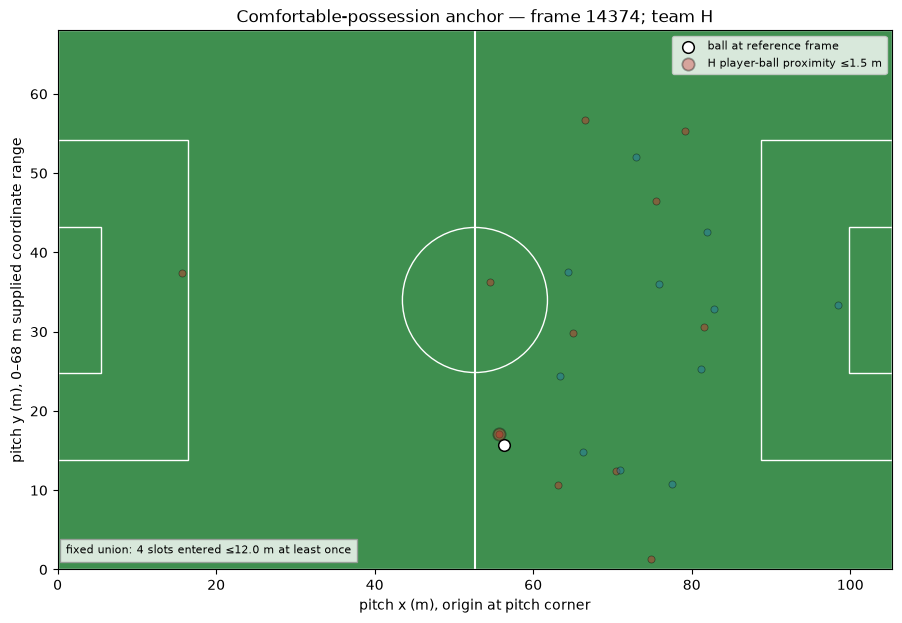

,frame,ball_x,ball_y,closest_team,closest_slot,closest_distance_m,team_distance_margin_m,candidate_pressure_m,candidate_opponent_density_5m,controlled_reception_evidence_score,selected_anchor_source
14374,14374,0.53444,0.23188,H,11.0,1.440039,8.662215,10.673962,0.0,0.621175,pressure_anchor_team


In [3]:
# Purpose: show one data-selected comfortable-possession anchor as a football-pitch snapshot.
comfortable = features.get('low_pressure_control', pd.Series(False, index=features.index)).fillna(False)
comfortable &= features.get('selected_anchor_team', pd.Series(index=features.index)).notna()
candidates = features.loc[comfortable & features.frame.between(PUBLIC_START, PUBLIC_END)]
if candidates.empty:
    print('No comfortable-control anchor was found in the public interval.')
else:
    row = candidates.iloc[0]
    anchor_frame = int(row.frame)
    fig, ax = plt.subplots(figsize=(11, 7))
    plot_trajectory_window(features, anchor_frame, anchor_frame, team_by_slot=team_by_slot, reference_frame=anchor_frame, ax=ax)
    ax.set_title(f'Comfortable-possession anchor — frame {anchor_frame}; team {row.selected_anchor_team}')
    plt.show()
    evidence_cols = [c for c in ['frame','ball_x','ball_y','closest_team','closest_slot','closest_distance_m','team_distance_margin_m','candidate_pressure_m','candidate_opponent_density_5m','controlled_reception_evidence_score','selected_anchor_source','selected_anchor_confidence_score'] if c in features]
    display(features.loc[features.frame.eq(anchor_frame), evidence_cols])


,case,representative_frame
0,comfortable anchor,14374
1,pressured or contested,11347
2,ball in flight / reception race,11260
3,genuine reception / transition,12704


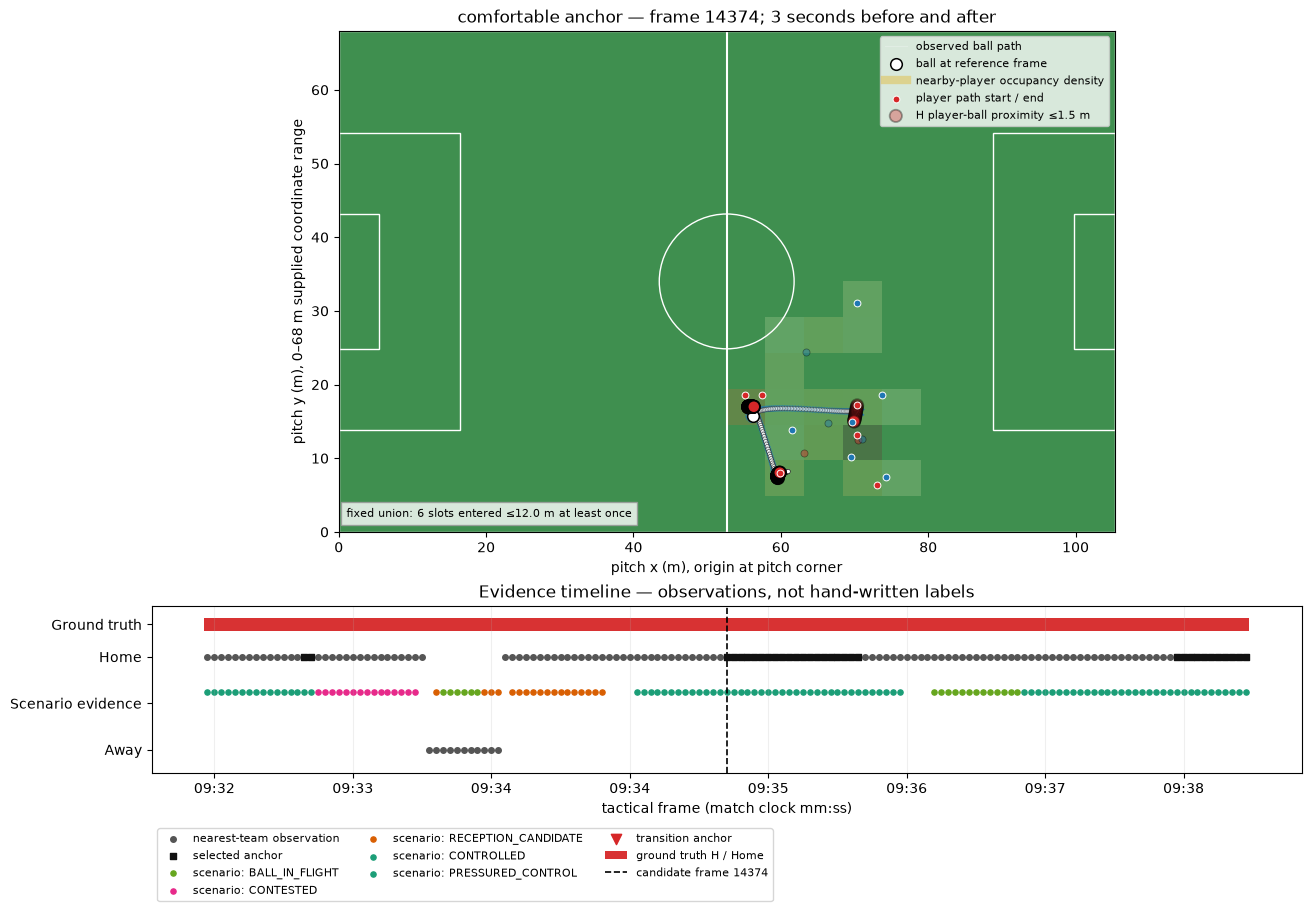

,frame,closest_team,closest_distance_m,team_distance_margin_m,candidate_pressure_m,candidate_opponent_density_5m,arrival_time_margin_s,ball_speed_derived_mps,scenario_context,selected_anchor_source,selected_anchor_confidence,genuine_reception_anchor,transition_anchor
14369,14369,H,1.350573,8.963039,11.220613,0.0,0.411909,1.090498,CONTROLLED,NO_ANCHOR,0.000000,False,False
14370,14370,H,1.377058,8.901746,11.163735,0.0,0.343244,0.849825,CONTROLLED,NO_ANCHOR,0.000000,False,False
14371,14371,H,1.402199,8.836586,11.106003,0.0,0.282222,0.650813,CONTROLLED,NO_ANCHOR,0.000000,False,False
14372,14372,H,1.420471,8.776182,11.024848,0.0,0.222489,0.462033,CONTROLLED,NO_ANCHOR,0.000000,False,False
14373,14373,H,1.433680,8.716511,10.849114,0.0,0.176682,0.343975,CONTROLLED,NO_ANCHOR,0.000000,False,False
14374,14374,H,1.440039,8.662215,10.673962,0.0,0.149642,0.327099,CONTROLLED,pressure_anchor_team,0.950000,False,False
14375,14375,H,1.439116,8.614603,10.498796,0.0,0.129307,0.403987,CONTROLLED,pressure_anchor_team,0.935620,False,False
14376,14376,H,1.429635,8.575895,10.323062,0.0,0.106568,0.546376,CONTROLLED,pressure_anchor_team,0.923369,False,False
14377,14377,H,1.413570,8.543905,10.148133,0.0,0.121362,0.656270,CONTROLLED,pressure_anchor_team,0.929446,False,False
14378,14378,H,1.390923,8.520492,9.973994,0.0,0.124408,0.757123,CONTROLLED,pressure_anchor_team,0.931137,False,False


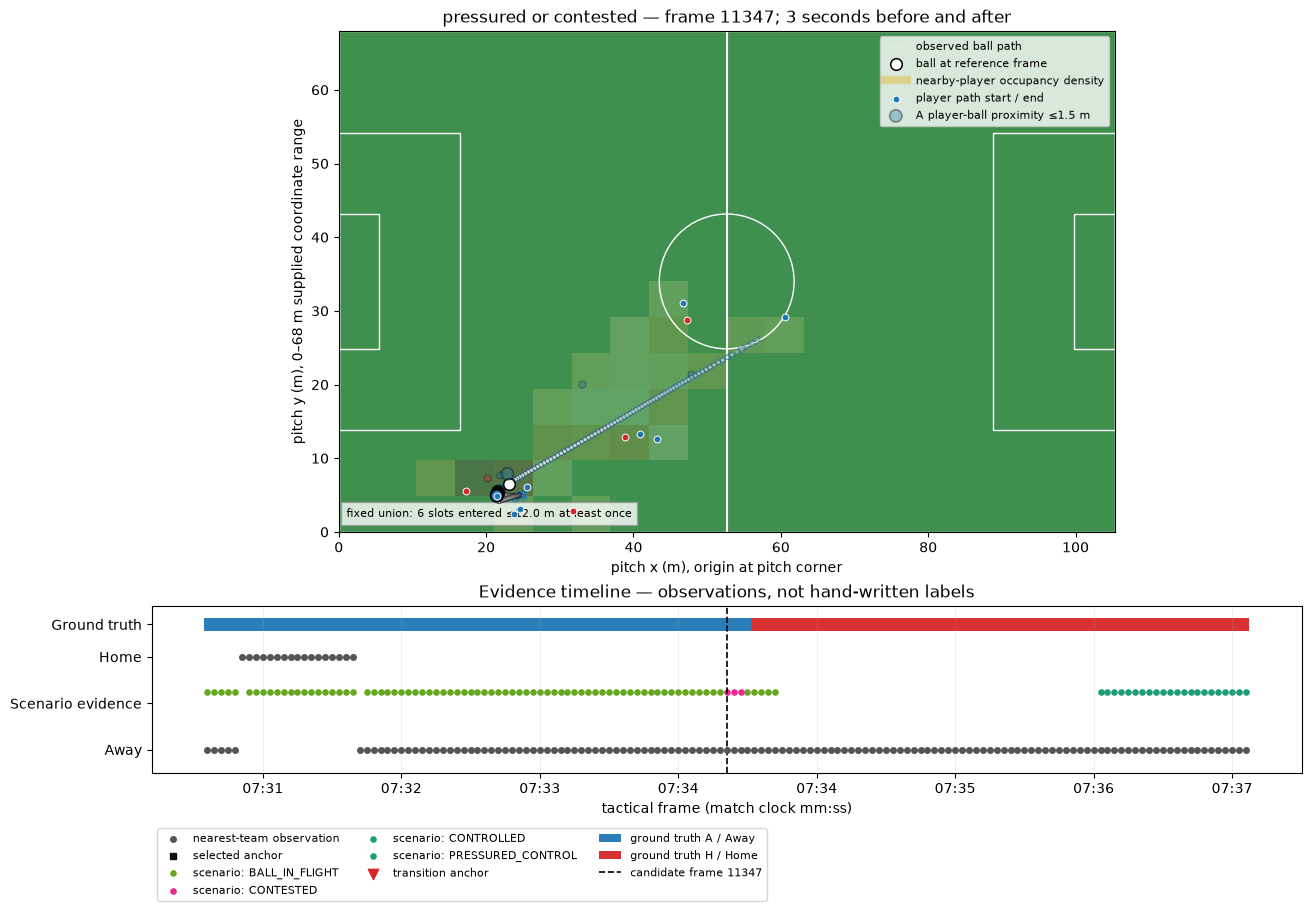

,frame,closest_team,closest_distance_m,team_distance_margin_m,candidate_pressure_m,candidate_opponent_density_5m,arrival_time_margin_s,ball_speed_derived_mps,scenario_context,selected_anchor_source,selected_anchor_confidence,genuine_reception_anchor,transition_anchor
11342,11342,A,1.517274,-1.636672,1.705795,1.0,-2.963226,10.409459,BALL_IN_FLIGHT,NO_ANCHOR,0.0,False,False
11343,11343,A,1.497500,-1.595434,1.712809,1.0,-2.918427,9.911656,BALL_IN_FLIGHT,NO_ANCHOR,0.0,False,False
11344,11344,A,1.513599,-1.541387,1.720131,1.0,-2.917817,9.355148,BALL_IN_FLIGHT,NO_ANCHOR,0.0,False,False
11345,11345,A,1.557982,-1.481035,1.730950,1.0,-2.878907,8.795336,BALL_IN_FLIGHT,NO_ANCHOR,0.0,False,False
11346,11346,A,1.629091,-1.417927,1.745631,1.0,-2.834256,8.177671,BALL_IN_FLIGHT,NO_ANCHOR,0.0,False,False
11347,11347,A,1.720893,-1.356062,1.762810,1.0,-2.801243,7.583526,CONTESTED,NO_ANCHOR,0.0,False,False
11348,11348,A,1.829484,-1.298737,1.782934,1.0,-2.753584,6.928100,CONTESTED,NO_ANCHOR,0.0,False,False
11349,11349,A,1.951668,-1.249076,1.807208,1.0,-2.719608,6.262424,CONTESTED,NO_ANCHOR,0.0,False,False
11350,11350,A,2.083142,-1.208907,1.833760,1.0,-2.637768,5.642968,BALL_IN_FLIGHT,NO_ANCHOR,0.0,False,False
11351,11351,A,2.223957,-1.180195,1.865168,1.0,-2.601167,4.964623,BALL_IN_FLIGHT,NO_ANCHOR,0.0,False,False


In [4]:
# Purpose: plot two data-selected examples; the case table retains the full audit.
def _first_frame(mask, lo=PUBLIC_START + 75, hi=PUBLIC_END - 75):
    mask = pd.Series(mask, index=features.index).fillna(False).astype(bool)
    candidates = features.loc[mask & features.frame.between(lo, hi), 'frame']
    return int(candidates.iloc[0]) if not candidates.empty else None

case_masks = {
    'comfortable anchor': features.get('low_pressure_control', pd.Series(False, index=features.index)) & features.get('selected_anchor_team', pd.Series(index=features.index)).notna(),
    'pressured or contested': features.get('scenario_context', pd.Series('', index=features.index)).isin(['CONTESTED', 'PRESSURED_CONTROL']),
    'ball in flight / reception race': features.get('scenario_context', pd.Series('', index=features.index)).eq('BALL_IN_FLIGHT'),
    'genuine reception / transition': features.get('genuine_reception_anchor', pd.Series(False, index=features.index)) | features.get('transition_anchor', pd.Series(False, index=features.index)),
}
case_frames = {name: _first_frame(mask) for name, mask in case_masks.items()}
display(pd.DataFrame({'case': case_frames.keys(), 'representative_frame': case_frames.values()}))
for name, centre in list(case_frames.items())[:2]:
    if centre is None:
        print(f'{name}: no data-selected example in the public window')
        continue
    fig, axes = plot_evidence_window(features, centre - 75, centre + 75, team_by_slot=team_by_slot, ground_truth=gt_by_frame)
    axes[0].set_title(f'{name} — frame {centre}; 3 seconds before and after')
    axes[1].axvline(centre, color='black', ls='--', lw=1.2, label=f'candidate frame {centre}')
    axes[1].legend(loc='upper left', bbox_to_anchor=(0, -0.30), ncol=3, fontsize=8)
    plt.show()
    cols = [c for c in ['frame','closest_team','closest_distance_m','team_distance_margin_m','candidate_pressure_m','candidate_opponent_density_5m','arrival_time_margin_s','ball_speed_derived_mps','scenario_context','selected_anchor_source','selected_anchor_confidence','genuine_reception_anchor','transition_anchor'] if c in features]
    display(features.loc[features.frame.between(centre-5, centre+5), cols])

## D / set-piece boundary study

This section focuses first on the difficult `D` label. We inspect each restart type separately and look backward and forward for the first credible live-ball evidence.

- Smart Tagging identifies the restart context and type; it is not treated as the exact kick frame.
- The audit records ball visibility, restart activation, ball flight, and the first public H/A label after the restart.
- `first_half_gt.csv` is hand-annotated and is used only to generate insight tables/plots, never to build prediction features.
- Goal aftermath remains protected until a centre-circle restart begins from near-zero speed and physical activation follows.

,restart_type,events,mean_missing_share,median_restart_activation_delay,median_D_to_public_HA
0,Corner Kick,12,0.487037,166.0,150.0
1,Free Kick,5,0.405936,154.0,131.0
2,Goal Kick,10,0.268937,18.0,209.0
3,Kick Off (After Goal),4,0.726190,83.0,0.0
4,Kick Off (Start),2,0.357143,45.5,0.0
5,Throw-in,24,0.248012,93.0,153.0


,restart_type,start_frame,end_frame,tagged_frames,ball_missing_share,restart_active_frame,first_public_HA_frame,frames_to_restart_activation,frames_D_to_public_HA
0,Corner Kick,29608,30483,876,0.561644,29782.0,29785.0,174.0,3.0
1,Corner Kick,34651,35526,876,0.452055,34828.0,35423.0,177.0,595.0
2,Corner Kick,36939,37275,337,0.335312,37053.0,37385.0,114.0,332.0
3,Corner Kick,42614,43489,876,0.310502,42749.0,42923.0,135.0,174.0
4,Corner Kick,57368,58243,876,0.374429,57534.0,57660.0,166.0,126.0
5,Corner Kick,80913,81788,876,0.299087,81176.0,81176.0,263.0,0.0
6,Corner Kick,130321,131196,876,0.776256,130473.0,NaN,152.0,NaN
7,Corner Kick,136426,137301,876,0.344749,136680.0,NaN,254.0,NaN
8,Corner Kick,138063,138938,876,0.772831,138256.0,NaN,193.0,NaN
9,Corner Kick,146805,147680,876,0.437215,146875.0,NaN,70.0,NaN


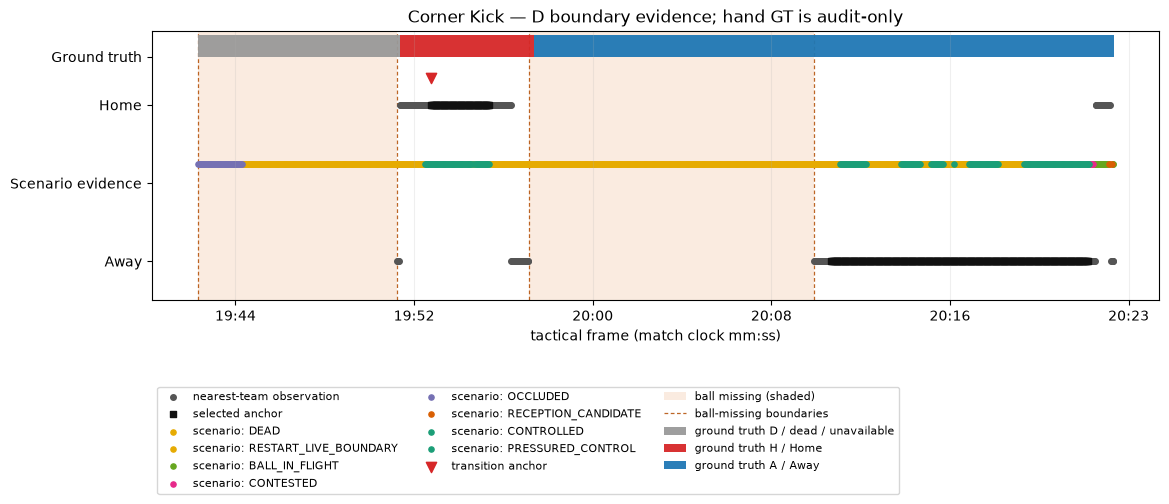

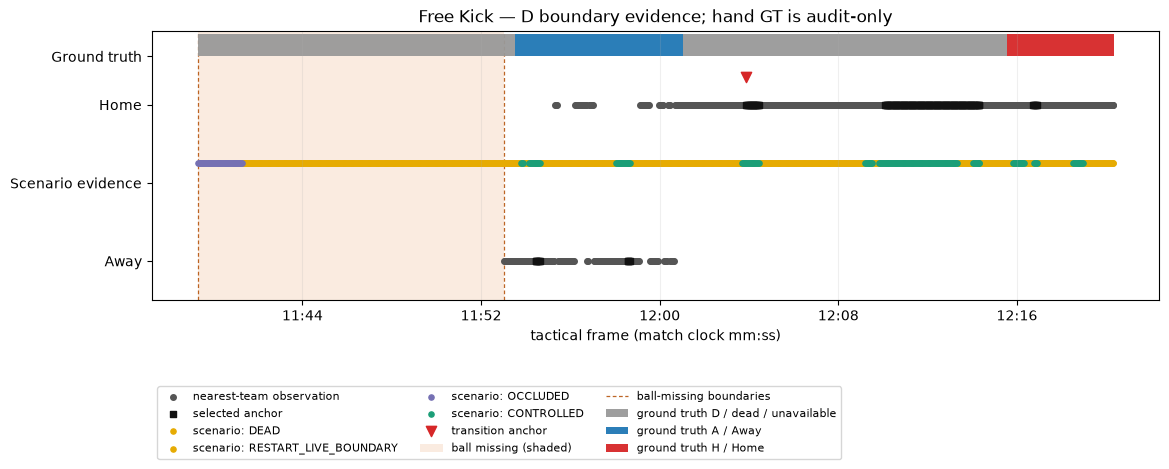

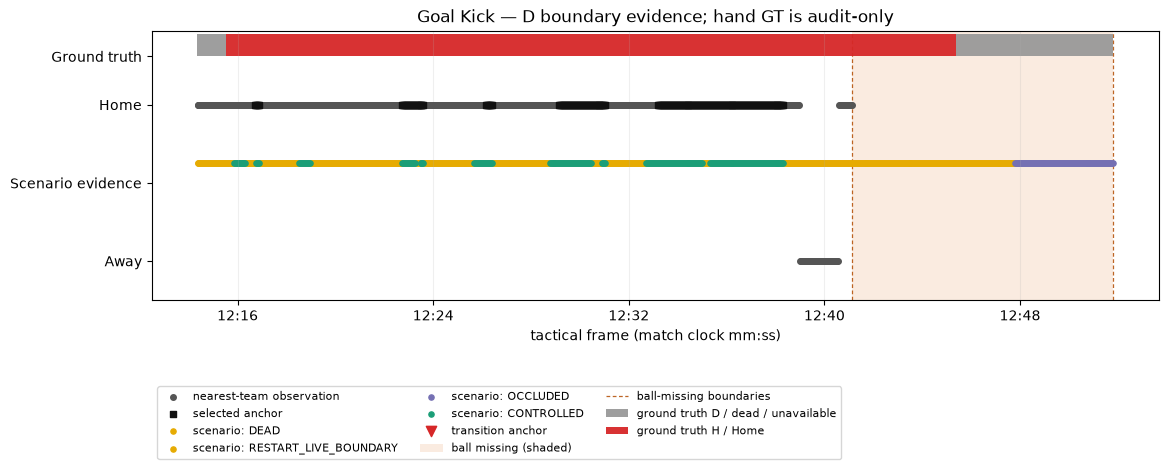

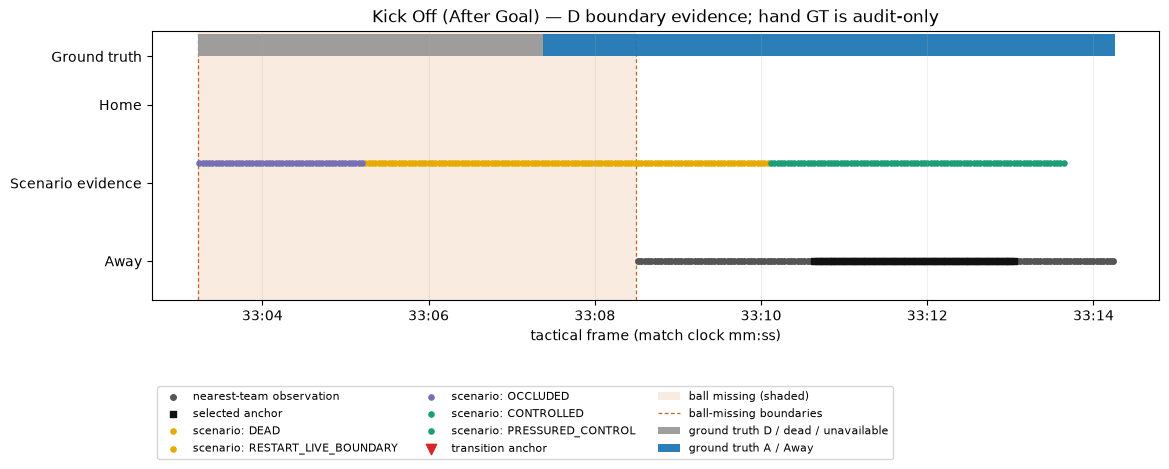

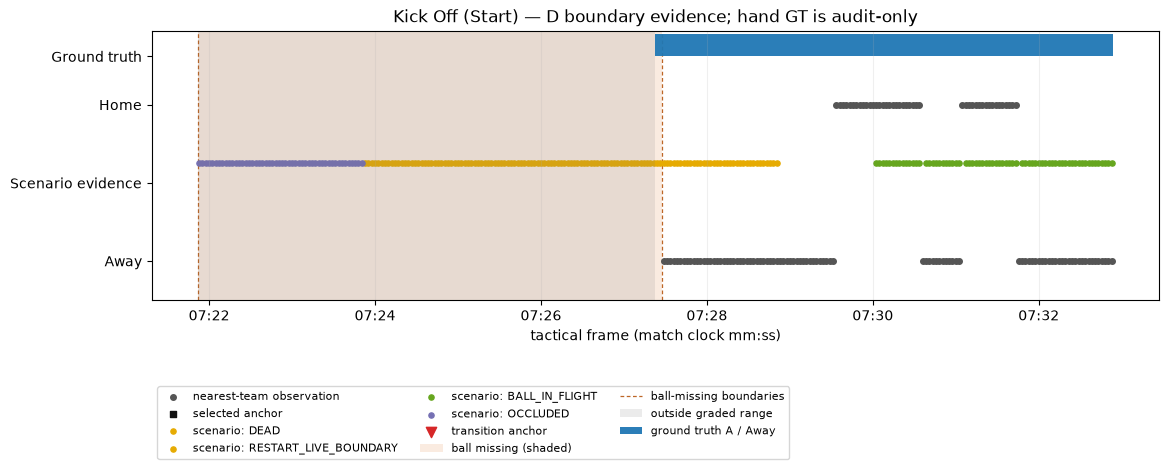

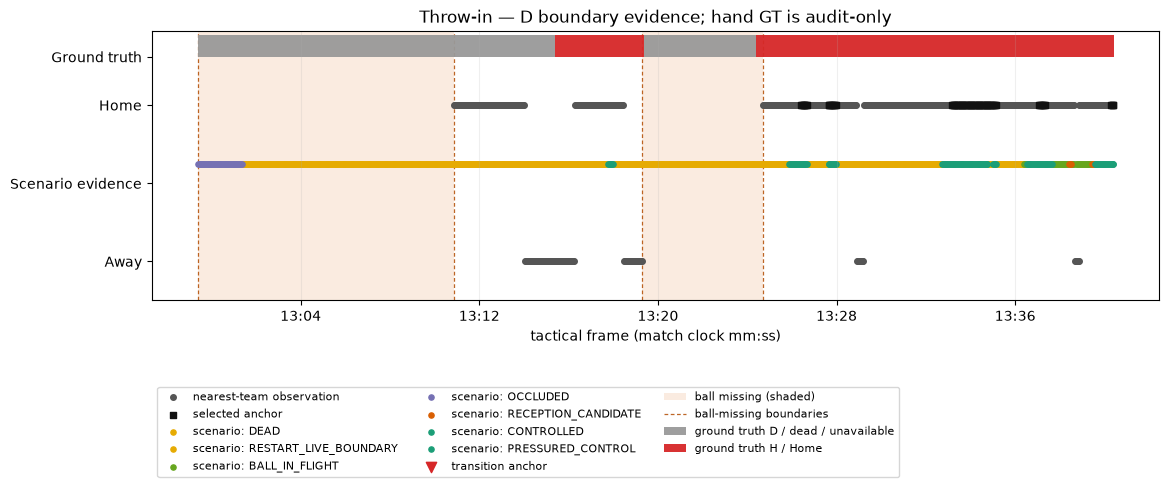

In [5]:
# Purpose: compare D-to-H/A boundary evidence by restart type.
from possession_lab.calculations.plotting import plot_timeline_window
insight_path = ROOT / 'data' / 'first_half_gt.csv'
insight_gt = pd.read_csv(insight_path).set_index('frame')['label'] if insight_path.exists() else gt_by_frame
restart_types = features.get('smart_restart_type', pd.Series(index=features.index, dtype=object))
restart_table = []
representatives = {}
for restart_type in sorted(restart_types.dropna().unique()):
    mask = restart_types.eq(restart_type).to_numpy(bool)
    starts = np.flatnonzero(mask & ~np.r_[False, mask[:-1]])
    ends = np.flatnonzero(mask & ~np.r_[mask[1:], False])
    for start, end in zip(starts, ends):
        start_frame, end_frame = int(features.iloc[start].frame), int(features.iloc[end].frame)
        local = features.loc[features.frame.between(start_frame, end_frame)]
        active = features.loc[features.frame.between(start_frame, end_frame) & features.get('restart_ball_active', pd.Series(False, index=features.index)).fillna(False)]
        active_frame = int(active.iloc[0].frame) if not active.empty else None
        boundary_frame = active_frame if active_frame is not None else end_frame
        future_gt = insight_gt.loc[insight_gt.index >= boundary_frame] if insight_gt is not None else pd.Series(dtype=object)
        ha = future_gt[future_gt.isin(['H','A'])]
        first_ha = int(ha.index[0]) if len(ha) else None
        restart_table.append({'restart_type': restart_type, 'start_frame': start_frame, 'end_frame': end_frame, 'tagged_frames': len(local), 'ball_missing_share': float(((local.ball_x.isna()) | (local.ball_y.isna())).mean()), 'restart_active_frame': active_frame, 'first_public_HA_frame': first_ha, 'frames_to_restart_activation': active_frame - start_frame if active_frame is not None else None, 'frames_D_to_public_HA': first_ha - boundary_frame if first_ha is not None else None})
        representatives.setdefault(restart_type, (max(int(features.frame.min()), start_frame - 50), min(int(features.frame.max()), end_frame + 100)))
restart_summary = pd.DataFrame(restart_table)
display(restart_summary.groupby('restart_type', as_index=False).agg(events=('restart_type','size'), mean_missing_share=('ball_missing_share','mean'), median_restart_activation_delay=('frames_to_restart_activation','median'), median_D_to_public_HA=('frames_D_to_public_HA','median')))
display(restart_summary)
for restart_type, (left, right) in representatives.items():
    fig, ax = plot_timeline_window(features, left, right, ground_truth=insight_gt)
    ax.set_title(f'{restart_type} — D boundary evidence; hand GT is audit-only')
    plt.show()